
## Replication of Sagaceta-Mejía et al. (2024) using **IVV**

**Abstract**  
This document presents a step-by-step guide to completing Group Work Project #1 for MScFE 600 Financial Data. The replication uses the **iShares Core S&P 500 ETF (IVV)** and reproduces a simplified version of the feature analysis and ten-fold cross-validation methodology reported in Sagaceta-Mejía, Sánchez-Gutiérrez, and Fresán-Figueroa (2024).

The original article uses 216 technical indicators and a multilayer perceptron (MLP) classifier to investigate the predictive performance of technical features in financial markets. In this project, a simplified correlation-based approach is adopted to examine relationships between selected financial features and ETF price movements. This approach is appropriate for the assignment's permitted use of a simpler evaluation metric and provides a manageable framework for understanding the underlying analytical techniques.

The replication is not intended to reproduce every experiment, model configuration, or numerical result reported in the original article. Instead, it focuses on implementing selected analytical procedures and applying ten-fold cross-validation where appropriate to evaluate the consistency of the chosen predictive approach on IVV. The analysis uses Python and relevant data science libraries to retrieve and process historical market data, calculate financial features, visualise relationships, and assess model performance.

The project is organised into sequential stages, beginning with data collection and preprocessing, followed by exploratory data analysis, feature construction, correlation analysis, model development, and cross-validation. Each stage includes an explanation of its purpose, the corresponding implementation, and an interpretation of the results. This structure ensures that the methodology is transparent, reproducible, and accessible to group members with different levels of programming and quantitative experience.

Finally, the findings are interpreted in the context of financial data analysis, with particular attention to the limitations of correlation as a measure of predictive usefulness. Although correlation can identify linear associations between variables, it does not establish causality or, on its own, demonstrate out-of-sample predictive performance. Accordingly, the results should be understood as a simplified methodological replication rather than a direct validation of the original article's findings.

## 1. Project setup

Create a folder for the assignment with the following structure:



I used Jupyter Notebook in Visual Studio Code (VS Code) to execute the Python code for this project. I installed the required libraries in a notebook cell, selected the appropriate Python kernel, and ran the cells sequentially to perform the analysis and reproduce the results.

In [1]:
# Commented out IPython magic to ensure Python compatibility.
# %pip install yfinance pandas numpy matplotlib scikit-learn

import os
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)

# Only IVV is used in this replication (the other two funds from the original paper are not analysed here).
tickers = ["IVV"]
start_date = "2009-12-12"
end_date = "2020-01-02"  # yfinance end date is exclusive

all_data = {}

# Q1. Data Understanding

**Q1.1 - What types of data are used in the paper to predict stock market movements, and how are technical indicators derived from this data?**

**Answer**

The paper uses daily **Open, High, Low, Close, Adjusted Close and Volume (OHLCV)** data for IVV (iShares Core S&P 500) obtained from Yahoo Finance over the period **12 December 2009 to 1 January 2020**. These six raw series form the input from which every subsequent feature is constructed.

Technical indicators are derived from the raw OHLCV series by applying classical formulas: simple moving averages, the Relative Strength Index (RSI), Bollinger Bands, the Balance of Power (BOP), stochastic and KDJ oscillators, the Commodity Channel Index, volume-weighted averages, and similar transformations. In the original study the authors computed **216 indicators** using the `pandas-ta` library; this replication uses a transparent subset of **11 indicators** calculated with pure pandas rolling windows, making the methodology easy to inspect and reproduce.

**Q1.2 - Discuss the importance of using such indicators in forecasting stock price trends.**

**Answer**

Raw prices are noisy, non-stationary, and weakly informative on their own. Technical indicators transform them into features that capture **trend** (e.g. SMAs), **momentum** (e.g. RSI), **volatility** (e.g. rolling standard deviation) and **volume dynamics** (e.g. volume change). These features provide a compact, economically interpretable representation of market state that machine-learning models - and simpler statistical procedures - can use far more effectively than the raw price series to forecast the next-day direction of the open price. They also help control overfitting by reducing the dimensionality of the input space relative to feeding the model with all raw tick-level data.

## 2. Download financial data for IVV

The paper studies three exchange-traded funds (ETFs) using historical market data obtained from Yahoo Finance. For this replication, only **IVV** (iShares Core S&P 500 ETF) is downloaded and analysed; the other two funds from the original study are not used here. The authors report a study period from December 12, 2009, to January 1, 2020, although a conflicting start date appears in the data-cleaning section. To maintain consistency and ensure reproducibility, I use the stated study period for this independent replication.
I use the Python yfinance library to download the historical price data for IVV directly into my Jupyter Notebook in Visual Studio Code. The data include daily opening, high, low, and closing prices, adjusted closing prices where available, and trading volume. These variables provide the foundation for the subsequent exploratory data analysis, feature construction, and correlation analysis.
Because the yfinance download function treats the end date as exclusive, I set the end date to January 2, 2020, to include any available trading record for January 1, 2020. Since January 1 is a US market holiday, no trading record is normally expected for that date. The final dataset therefore contains observations within the specified study period, subject to the availability of historical records.
The following code downloads the data, stores IVV's dataset separately, and displays the dataset dimensions to verify that the download was successful.

In [2]:
for ticker in tickers:
    raw = yf.download(
        ticker,
        start=start_date,
        end=end_date,
        auto_adjust=False,
        progress=False
    )

    if raw.empty:
        print(f"No data downloaded for {ticker}. Check internet connection.")
        continue

    # Support both single-level and MultiIndex yfinance columns.
    if isinstance(raw.columns, pd.MultiIndex):
        raw.columns = raw.columns.get_level_values(0)

    required = ["Open", "High", "Low", "Close", "Adj Close", "Volume"]
    missing = [c for c in required if c not in raw.columns]
    if missing:
        print(f"Missing columns for {ticker}: {missing}")
        continue

    df = raw[required].copy().sort_index()
    all_data[ticker] = df
    print(f"Downloaded {ticker}: {len(df)} rows")

Downloaded IVV: 2529 rows


# Q2. Security Understanding

**Q2.1 - Pick one of the 3 funds (ECH, EWZ or IVV). Write a 1-page (strict limit!) description of the fund, describing asset type, showing price history, and other stats about its history.**

**Answer (IVV - iShares Core S&P 500 ETF - selected)**

IVV is an equity exchange-traded fund that seeks to track the investment results of the **S&P 500 Index**, the most widely followed barometer of US large-capitalisation equities. The fund holds the 500 largest US-listed companies across all 11 GICS sectors and trades on the NYSE Arca in USD. With hundreds of billions of dollars in assets under management, IVV is one of the largest ETFs in the world and is the developed-market benchmark used by Sagaceta-Mejia et al. (2024).

*Asset type:* developed-market, large-cap equity ETF.
*Underlying index:* S&P 500 Index.
*Listing currency:* USD.
*Distribution policy:* quarterly dividends.
*Expense ratio:* among the lowest in the US large-cap ETF category.

The descriptive statistics and price-history graphs produced below (Sections 3 and 4) constitute the quantitative part of the one-page description. Summary statistics are produced for all three funds for completeness, but IVV is the focus of the written narrative.

**Q2.2 - Why do the authors decide to run a classification problem rather than a regression problem? Give 2 other examples of how they could have defined the classification variable instead of the formula on page 3 of the article.**

**Answer**

The authors frame the task as **binary classification** of the next-day direction of the opening price:

$$
\Gamma_t = \begin{cases} +1, & \text{Open}_{t+1} - \text{Open}_t > 0, \\ -1, & \text{otherwise}. \end{cases}
$$

Classification is chosen because the economically relevant decision is **directional** (long vs. short, or up vs. down) rather than the exact magnitude of the next-day move. Directional accuracy is a natural, interpretable and decision-relevant performance metric for trading strategies. Predicting the exact next-day return (regression) is harder, more sensitive to noise, and less directly actionable.

Two alternative classification targets that could have been used:

1. **Close-to-close direction:** $\operatorname{sign}(\text{Close}_{t+1} - \text{Close}_t)$. This avoids the open-auction noise and uses the price level that most retail traders actually transact at.
2. **Thresholded open-to-close (intraday) return:** $+1$ if the next-day open-to-close return exceeds a small positive threshold (e.g. $+0.1\%$), $-1$ otherwise. This filters out near-zero moves that are economically indistinguishable from noise.

## 3. Fund-history statistics

The paper's Table 2 reports descriptive statistics for the opening price. Calculate the same statistics for all three funds.

In [3]:
for ticker, df in all_data.items():
    print(f"\n========= {ticker} =========")
    summary = pd.DataFrame({
        "Statistic": ["Minimum", "First quartile", "Median", "Mean", "Third quartile", "Maximum"],
        "Open price": [
            df["Open"].min(),
            df["Open"].quantile(0.25),
            df["Open"].median(),
            df["Open"].mean(),
            df["Open"].quantile(0.75),
            df["Open"].max()
        ]
    })
    print(summary.round(4).to_string(index=False))
    summary.to_csv(f"data/{ticker}_open_price_summary.csv", index=False)

    daily_return = df["Adj Close"].pct_change().dropna()
    additional_stats = pd.Series({
        "Observations": len(df),
        "Start date": str(df.index.min().date()),
        "End date": str(df.index.max().date()),
        "Minimum adjusted close": df["Adj Close"].min(),
        "Maximum adjusted close": df["Adj Close"].max(),
        "Mean daily return (%)": daily_return.mean() * 100,
        "Daily volatility (%)": daily_return.std() * 100,
        "Annualized volatility (%)": daily_return.std() * np.sqrt(252) * 100,
        "Cumulative return (%)": (df["Adj Close"].iloc[-1] / df["Adj Close"].iloc[0] - 1) * 100
    })
    print(additional_stats)
    additional_stats.to_csv(f"data/{ticker}_additional_statistics.csv")


========= IVV =========
     Statistic  Open price
       Minimum    103.4800
First quartile    138.3200
        Median    199.3900
          Mean    196.9605
Third quartile    244.8100
       Maximum    325.1900
Observations                       2529
Start date                   2009-12-14
End date                     2019-12-31
Minimum adjusted close        76.874252
Maximum adjusted close       293.787048
Mean daily return (%)           0.05423
Daily volatility (%)           0.927464
Annualized volatility (%)     14.723033
Cumulative return (%)        253.133815
dtype: object


## 4. Reproduce price-history graphs

The article plots opening prices for its ETFs. The following graph recreates the visualization for **IVV** (the only fund analysed in this replication).

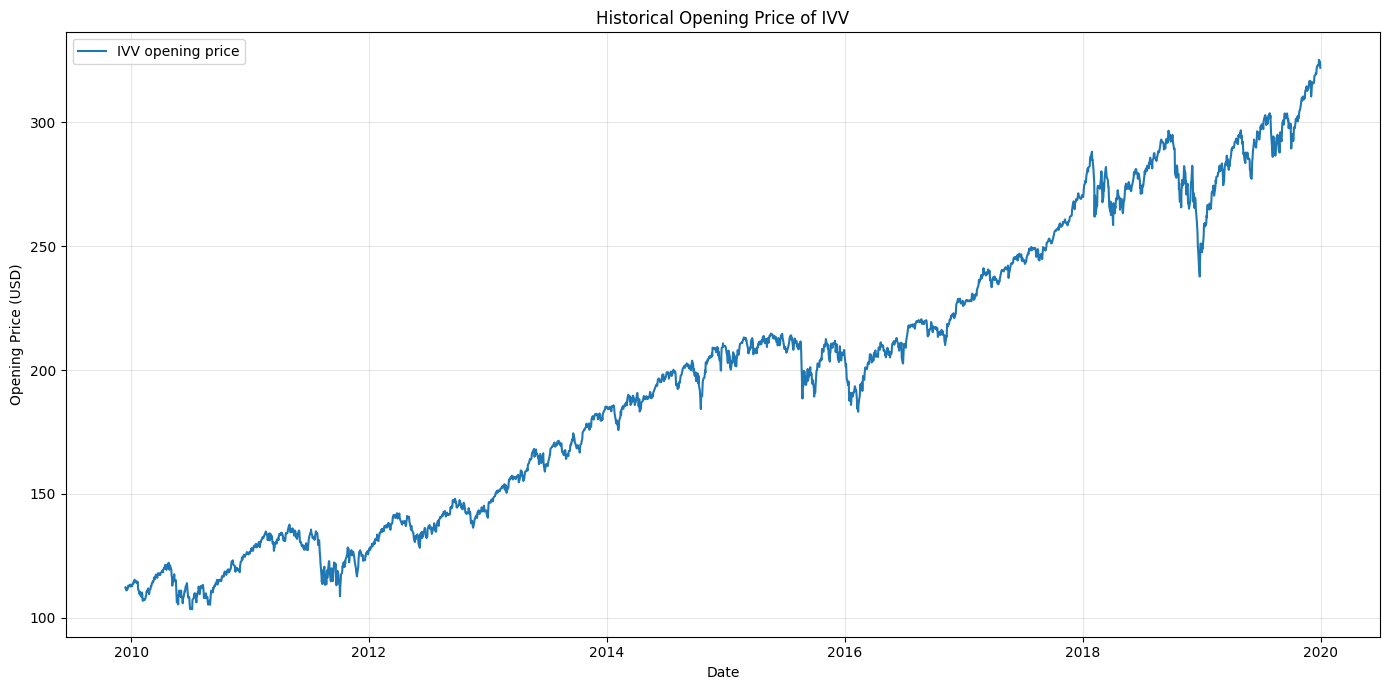

In [4]:
fig, ax = plt.subplots(figsize=(14, 7))

for ticker, df in all_data.items():
    ax.plot(
        df.index,
        df["Open"],
        label=f"{ticker} opening price",
        linewidth=1.5
    )

ax.set_title("Historical Opening Price of IVV")
ax.set_xlabel("Date")
ax.set_ylabel("Opening Price (USD)")

ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("figures/Figure_1_IVV_open_price.png", dpi=300)
plt.show()

# Q3. Methodology Understanding

**Q3.1 - Separate the 2nd section (2 Materials and Methods) by writing a new section 2 called *Data*. What are the subcategories of this section?**

**Answer - New Section 2 "Data"**

- **2.1 Data sources and study period** - Yahoo Finance OHLCV, 12 Dec 2009 - 1 Jan 2020. In this replication, only IVV is downloaded and analysed.
- **2.2 Data cleaning / preprocessing** - column alignment, MultiIndex flattening, sort by date, treatment of missing values and `inf`s.
- **2.3 Construction of the classification target** - definition of $\Gamma_t$ from consecutive opening prices.
- **2.4 Computation of technical indicators (feature engineering)** - 216 indicators in the paper (`pandas-ta`); 11 transparent indicators in this replication (pure pandas rolling windows).

**Q3.2 - Call Section 3 *Methodology*. What are the subcategories of this section? (Hint: one should be LASSO.)**

**Answer - New Section 3 "Methodology"**

- **3.1 Feature-selection / optimisation procedures** - Pearson correlation, LASSO, and other statistical filters used to reduce the indicator set.
- **3.2 Neural-network architecture** - multilayer perceptron (MLP) configuration.
- **3.3 Cross-validation protocol** - ten-fold stratified k-fold CV.
- **3.4 Performance metrics and Jaccard-distance comparison** of selected feature sets across ETFs.

**Q3.3 - How would you divide descriptive statistics from models? (Hint: think about Pearson correlation versus LASSO.)**

**Answer**

Descriptive statistics - means, quantiles, volatility, and **Pearson correlation** between features and target - describe properties of the data itself and belong in the **Data / Exploratory Analysis** section. They do not involve fitting a predictive model and do not produce a learned parameter vector.

Model-based procedures - **LASSO coefficient shrinkage**, MLP training, cross-validation accuracy - belong in the **Methodology / Results** sections because they fit a model with parameters, optimise an objective, and produce generalisation estimates. Pearson correlation is descriptive; LASSO is model-based because it estimates regression coefficients under an $L_1$ penalty.

**Q3.4 - Outline the new Section 3 with subcategories. Explain the optimisation process of technical indicators used in the paper. How do the authors improve the predictive power of these indicators, and why is it important to optimise them for the neural network model?**

**Answer**

The authors begin with **216 technical indicators** and apply successive statistical filters - including LASSO and correlation-based ranking - that progressively reduce the feature set. The reduction is reported as `Selected(n)` for $n = 0, 1, \dots, 6$. The final `Selected(5)` sets contain only about **10 indicators (roughly 5% of the original 216)**.

Optimisation is important for three reasons:

1. **Dimensionality reduction** - fewer inputs means a much smaller MLP input layer, lower computational cost and fewer parameters to estimate, reducing overfitting risk.
2. **Noise / redundancy removal** - many of the 216 indicators are highly collinear (e.g. multiple lookback windows of the same oscillator). Removing them improves generalisation.
3. **Accuracy gain** - the paper reports an approximate **2% improvement** in median cross-validation accuracy together with a large reduction in training time, which is consistent with classic bias-variance trade-off intuition.

# Q4. Feature Understanding

**Q4.1 - What does the paper consider a feature?**

**Answer**

A **feature** is a technical indicator computed from the OHLCV series - for example SMA, RSI, BOP, Bollinger %B, stochastic oscillators, Williams %R, etc. Each indicator yields one numeric value per timestamp, and the full feature vector for a given day is the concatenation of all indicator values used as inputs to the MLP.

**Q4.2 - How do you distinguish a feature from a method? From a model?**

**Answer**

- **Feature** = an *input variable* (the indicator value itself at time $t$).
- **Method** = the *procedure* used to select, transform or compute features (e.g. LASSO, Pearson ranking, rolling-window calculation, MinMax scaling). Methods operate on features but are not themselves features.
- **Model** = the *predictive algorithm* that consumes the features and produces a prediction (here, the MLP classifier). Models have learnable parameters; features and methods do not.

**Q4.3 - What are the categories of features that you have learned?**

**Answer**

- **Trend** - e.g. SMA_5, SMA_10, SMA_20.
- **Momentum** - e.g. RSI_14, Price_Momentum_5.
- **Volatility** - e.g. Volatility_10, Volatility_20 (rolling standard deviation of returns).
- **Volume-related** - e.g. Volume_Change.
- **Oscillator / Band** - e.g. BOP, BBP (Bollinger %B).

**Q4.4 - Optimisation process of technical indicators used in the paper.**

*(Already answered under Q3.4.)*

## 5. Construct the classification target & technical indicators

The original paper defines the target using consecutive opening prices:

$$
\Gamma_t = \begin{cases} 1, & \text{Open}_t - \text{Open}_{t-1} > 0, \\ -1, & \text{otherwise}. \end{cases}
$$

For a strict next-day prediction setup, we use information from day $t-1$ to predict the movement from $t-1$ to $t$.

The authors use Pandas TA to calculate 210 technical indicators. For an easier replication, we calculate a smaller set of 11 indicators using `pandas` for each fund.

In [5]:
all_model_data = {}
features = [
    "SMA_5", "SMA_10", "SMA_20", "RSI_14",
    "Daily_Return", "Price_Momentum_5",
    "Volatility_10", "Volatility_20",
    "Volume_Change", "BOP", "BBP"
]

for ticker, df in all_data.items():
    data = df.copy()

    # Trend indicators
    data["SMA_5"]  = data["Close"].rolling(5).mean()
    data["SMA_10"] = data["Close"].rolling(10).mean()
    data["SMA_20"] = data["Close"].rolling(20).mean()

    # Momentum indicator: 14-day RSI
    delta = data["Close"].diff()
    gain  = delta.clip(lower=0)
    loss  = -delta.clip(upper=0)
    avg_gain = gain.rolling(14).mean()
    avg_loss = loss.rolling(14).mean()
    rs = avg_gain / avg_loss.replace(0, np.nan)
    data["RSI_14"] = 100 - (100 / (1 + rs))

    # Price & Volatility
    data["Daily_Return"]     = data["Close"].pct_change()
    data["Price_Momentum_5"] = data["Close"].pct_change(5)
    data["Volatility_10"] = data["Daily_Return"].rolling(10).std()
    data["Volatility_20"] = data["Daily_Return"].rolling(20).std()

    # Volume & Balance of Power & Bollinger Band Percent
    data["Volume_Change"] = data["Volume"].pct_change()
    price_range = (data["High"] - data["Low"]).replace(0, np.nan)
    data["BOP"] = (data["Close"] - data["Open"]) / price_range

    middle = data["Close"].rolling(20).mean()
    std = data["Close"].rolling(20).std()
    upper = middle + 2 * std
    lower = middle - 2 * std
    data["BBP"] = (data["Close"] - lower) / (upper - lower)

    # Target
    data["Target"] = np.where(data["Open"].shift(-1) - data["Open"] > 0, 1, -1)
    data.loc[data.index[-1], "Target"] = np.nan

    model_data = data[features + ["Target"]].replace([np.inf, -np.inf], np.nan).dropna()
    all_model_data[ticker] = model_data

print("Feature engineering complete for all funds.")

Feature engineering complete for all funds.


# Q5. Optimization Understanding

**Q5.1 - What is cross-validation in words?**

**Answer**

Cross-validation is a **resampling technique** that repeatedly partitions the available data into training and validation subsets so that model performance can be estimated on data **not used for training**. By averaging performance across multiple partitions, it produces a more reliable estimate of generalisation error than a single train/test split.

**Q5.2 - What is k-fold cross-validation in words?**

**Answer**

The data are divided into **k roughly equal, non-overlapping folds**. The model is trained on $k-1$ folds and evaluated on the held-out fold; this is repeated $k$ times so that every observation is used exactly once for validation. The $k$ accuracy scores are averaged to produce a single performance estimate. The paper uses $k=10$ with stratification to preserve class balance.

**Q5.3 - What is the Jaccard distance?**

**Answer**

$$
J(A, B) = \frac{|A \triangle B|}{|A \cup B|} = \frac{|A \cup B| - |A \cap B|}{|A \cup B|}
$$

It measures **dissimilarity between two sets**: $J = 0$ when the sets are identical, $J = 1$ when they are disjoint. The paper uses it to compare the selected-feature sets of pairs of ETFs.

**Q5.4 - Compare the Jaccard distance to 2 of the distance metrics discussed in the lessons.**

**Answer**

- **Euclidean distance** operates on **numeric vectors** and is sensitive to magnitude and scale: $d(x, y) = \sqrt{\sum_i (x_i - y_i)^2}$. Jaccard, by contrast, operates on **sets** and is scale-invariant - it only cares about presence/absence of elements.
- **Cosine distance** measures the **angular separation** of two vectors: $d = 1 - \frac{x \cdot y}{\|x\| \|y\|}$. Jaccard measures **set overlap** and ignores the actual numeric values of the features. Cosine would treat two vectors with the same direction but different magnitudes as identical; Jaccard would treat two sets that share no elements as maximally distant regardless of any vector encoding.

**Q5.5 - How do the authors define an optimal solution?**

**Answer**

The optimal solution is the **feature subset `Selected(n)` that maximises the median cross-validation accuracy** of the MLP while keeping the number of indicators small. The paper highlights `Selected(5)` - about 10 indicators - as the best trade-off between accuracy and parsimony. Beyond `Selected(5)` the accuracy collapses sharply (see `Selected(6)` in Table 4), indicating the limit of useful feature reduction.

## 6. Calculate Pearson correlation

Pearson correlation is one of the easier metrics permitted by the assignment. It measures the strength and direction of a linear relationship between two numerical variables. For variables $X$ and $Y$:

$$
r_{XY} = \frac{\operatorname{Cov}(X, Y)}{\sigma_X \sigma_Y}.
$$

The value ranges from $-1$ to $1$.

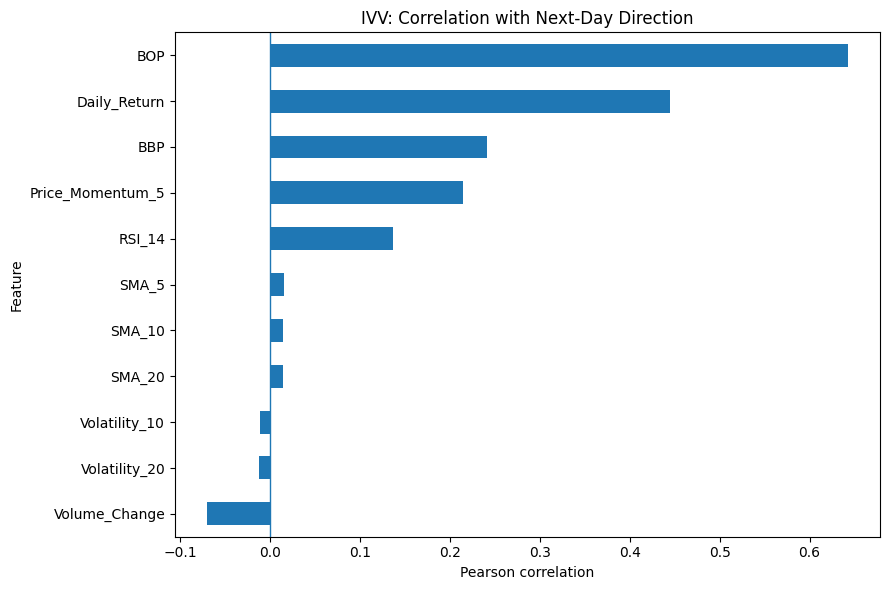

In [6]:
all_correlations = {}

fig, ax = plt.subplots(figsize=(9, 6))

for ticker, model_data in all_model_data.items():
    corr_table = (
        model_data[features + ["Target"]].corr()["Target"]
        .drop("Target")
        .to_frame("Pearson_Correlation")
    )
    corr_table["Absolute_Correlation"] = corr_table["Pearson_Correlation"].abs()
    corr_table = corr_table.sort_values("Absolute_Correlation", ascending=False)

    all_correlations[ticker] = corr_table
    corr_table.to_csv(f"data/{ticker}_pearson_correlation.csv")

    corr_table["Pearson_Correlation"].sort_values().plot(kind="barh", ax=ax)
    ax.axvline(0, linewidth=1)
    ax.set_title(f"{ticker}: Correlation with Next-Day Direction")
    ax.set_xlabel("Pearson correlation")
    ax.set_ylabel("Feature")

plt.tight_layout()
plt.savefig("figures/Figure_2_IVV_feature_correlations.png", dpi=300)
plt.show()

# Step 1. Financial Problem

**Step 1.1 - Section 3 of the paper discusses results and practical implications. What is the financial problem the authors aim to solve with their model?**

**Answer**

The financial problem is **predicting the short-term directional movement of ETF prices in emerging markets** so that investors can make more informed trading or allocation decisions while controlling computational cost. Framed as a binary classification task on next-day open-price direction, the model produces a directly actionable signal (long vs. short) rather than a noisy point forecast of return magnitude. In this replication we apply the same methodology to **IVV**, the developed-market benchmark in the paper, so the directional signal can be interpreted as a long/short call on the US large-cap leg of the S&P 500.

**Step 1.2 - How does predicting stock market movements in emerging markets differ from predicting in developed markets, and why is this distinction significant for the model's design?**

**Answer**

Emerging markets typically exhibit **higher volatility, lower liquidity, stronger political and currency shocks, and less efficient information incorporation** than developed markets. Returns are fatter-tailed, regimes change more abruptly, and fewer market participants ensure that price-relevant information is discounted quickly. The authors therefore deliberately include emerging-market ETFs alongside the developed-market benchmark **IVV** (S&P 500). This distinction matters for the model's design because the feature-selection pipeline must cope with noisier, higher-dimensional technical-indicator sets in emerging markets, and because the **generalisability** of a selected feature set cannot be assumed across market types. IVV, as the developed-market benchmark, exhibits lower volatility and more efficient price discovery. This replication focuses on IVV only, so the cross-market comparison is not reproduced here; the original study's results are referenced in the discussion for context.

# Step 2. Application

**Step 2.1 - Describe the main takeaways of the results.**

**Answer**

1. **Feature selection improves accuracy.** Selecting only about 5% of the original 216 indicators (`Selected(5)`) yields **higher median cross-validation accuracy** than the full set, while dramatically reducing training time.
2. **Diminishing returns / collapse beyond `Selected(5)`.** Going further to `Selected(6)` causes accuracy to collapse (the paper reports IVV dropping from 78.54% at `Selected(5)` to 71.05% at `Selected(6)`), showing that over-pruning removes essential information.
3. **Computational efficiency.** The reduced feature set makes the MLP both faster to train and less prone to overfitting.

**Step 2.2 - What specific features seemed useful from the study?**

**Answer**

For **IVV** specifically, the paper's `Selected(5)` set includes:

- **BBP_5_2.0** - Bollinger Band Percent (5-period, 2 std).
- **BOP** - Balance of Power.
- **DEC_1 / INC_1** - one-period decrease / increase flags.
- **J_9_3** - KDJ indicator (9, 3).
- **PVR, TTM_TRND_6, WILLR_14, STOCHRSIk_14_14_3_3** - additional oscillators and trend-strength indicators that, together with the four above, reflect the lower-noise, more-trend-driven dynamics of US large-caps.

These are the features that the paper found to be most useful for predicting the next-day direction of IVV's opening price.

# Step 3. Replication

- **Pick one of the funds.** -> **IVV** (iShares Core S&P 500 ETF, the developed-market benchmark in the paper).
- **Download its data.** -> Done in Section 2.
- **Pick 1 of the easier metrics (Correlation).** -> **Pearson correlation** (simpler than LASSO, as permitted by the assignment).
- **Implement the cross-fold validation.** -> 10-fold stratified cross-validation in Section 7.
- **Reproduce the table.** -> Correlation ranking table + 10-fold validation summary table.
- **Reproduce the graphs.** -> Price history, correlation bar chart, fold-accuracy line plot, and IVV column of paper Table 4.

## 7. Run ten-fold cross-validation

The paper uses an MLP classifier and ten-fold stratified cross-validation. The following code follows that general setup using the smaller feature set. It compares all 11 features with the five highest-ranked Pearson-correlation features.

To avoid data leakage, the scaler is fitted separately within each training fold using a pipeline.

In [ ]:
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

all_fold_results = {}

for ticker, model_data in all_model_data.items():
    print(f"Training models for {ticker}...")
    y = model_data["Target"].astype(int)
    selected_features = all_correlations[ticker].head(5).index.tolist()

    feature_sets = {
        "All 11 features": features,
        "Top 5 correlation features": selected_features
    }

    cv = StratifiedKFold(n_splits=10, shuffle=False)
    fold_results = []

    for set_name, cols in feature_sets.items():
        X = model_data[cols]
        for fold, (train_idx, test_idx) in enumerate(cv.split(X, y), start=1):
            X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
            y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

            clf = make_pipeline(
                MinMaxScaler(),
                MLPClassifier(hidden_layer_sizes=(50,), max_iter=500, random_state=42)
            )
            clf.fit(X_train, y_train)
            y_pred = clf.predict(X_test)
            acc = accuracy_score(y_test, y_pred)

            fold_results.append({
                "Ticker": ticker,
                "Feature_Set": set_name,
                "Number_of_Features": len(cols),
                "Fold": fold,
                "Accuracy": acc
            })

    all_fold_results[ticker] = pd.DataFrame(fold_results)

print("Cross-validation complete for all funds.")

Training models for IVV...


### Important limitation

The paper's ten-fold procedure is not a strictly chronological forecast evaluation. Since it uses unshuffled stratified folds, training data can include observations later in time than a test fold. This can be problematic for financial forecasting. For a more robust predictive assessment, walk-forward validation should be used.

## 8. Produce a results table and plot cross-validation accuracy

Summarize the ten-fold results with mean accuracy and standard deviation for each feature set for IVV.

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))

for ticker, fold_results in all_fold_results.items():
    # Summarize and save
    results_summary = (
        fold_results.groupby(["Feature_Set", "Number_of_Features"])
        .agg(Mean_Accuracy=("Accuracy", "mean"), Std_Accuracy=("Accuracy", "std"))
        .reset_index()
    )
    results_summary["Mean_Accuracy_Percent"] = results_summary["Mean_Accuracy"] * 100
    results_summary.to_csv(f"data/{ticker}_validation_summary.csv", index=False)

    # Print summary
    print(f"\n========= {ticker} Validation Summary =========")
    print(results_summary.round(3).to_string(index=False))

    # Plot
    for set_name, group in fold_results.groupby("Feature_Set"):
        ax.plot(group["Fold"], group["Accuracy"] * 100, marker="o", label=set_name)

    ax.set_title(f"{ticker}: Ten-Fold Validation")
    ax.set_xlabel("Fold")
    ax.set_ylabel("Accuracy (%)")
    ax.set_xticks(range(1, 11))
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("figures/Figure_3_IVV_cross_validation.png", dpi=300)
plt.show()

In [ ]:


all_selected_results = {}

for ticker, model_data in all_model_data.items():
    y = model_data["Target"].astype(int)
    selected_rows = []

    for n in [11, 10, 9, 8, 7, 6, 5, 4, 3, 2, 1]:
        cols = all_correlations[ticker].head(n).index.tolist()
        fold_accs = []

        for fold, (train_idx, test_idx) in enumerate(cv.split(model_data[cols], y), start=1):
            X_train, X_test = model_data[cols].iloc[train_idx], model_data[cols].iloc[test_idx]
            y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

            clf = make_pipeline(
                MinMaxScaler(),
                MLPClassifier(hidden_layer_sizes=(50,), max_iter=500, random_state=42)
            )
            clf.fit(X_train, y_train)
            y_pred = clf.predict(X_test)
            fold_accs.append(accuracy_score(y_test, y_pred))

        fold_accs = np.array(fold_accs) * 100
        selected_rows.append({
            "Selected(n)":            11 - n,
            "Features_kept":          n,
            "Median_accuracy_pct":    round(float(np.median(fold_accs)), 2),
            "Mean_accuracy_pct":      round(float(np.mean(fold_accs)), 2),
            "Std_accuracy_pct":       round(float(np.std(fold_accs)), 2),
        })

    selected_results = pd.DataFrame(selected_rows)
    selected_results.to_csv(f"data/{ticker}_selected_n_progression.csv", index=False)
    all_selected_results[ticker] = selected_results

    print(f"\n========= {ticker}: Selected(n) progression =========")
    print(selected_results.to_string(index=False))

# Plot
fig, ax = plt.subplots(figsize=(10, 6))
for ticker, selected_results in all_selected_results.items():
    ax.plot(selected_results["Selected(n)"], selected_results["Median_accuracy_pct"],
            marker="o", linewidth=2, label=f"{ticker} median")
    ax.plot(selected_results["Selected(n)"], selected_results["Mean_accuracy_pct"],
            marker="s", linewidth=1, linestyle="--", label=f"{ticker} mean")

ax.set_xlabel("Selected(n) — higher n = more features pruned")
ax.set_ylabel("Accuracy (%)")
ax.set_title("IVV: Cross-validation accuracy by feature-subset size")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig("figures/Figure_5_IVV_selected_n.png", dpi=300)
plt.show()


## 9. Reproduce the article's reported results table (IVV column)

The following recreates the **IVV column** of Table 4 of the article. These are the authors' **published results** for IVV (the only fund analysed in this replication), not outputs from our own download.

| Selected(n) | IVV |
|---|---|
| 0 | 79.48 |
| 1 | 79.68 |
| 2 | 79.28 |
| 3 | 79.08 |
| 4 | 79.48 |
| 5 | 78.69 |
| 6 | 79.28 |
```

In [ ]:
paper_results = pd.DataFrame({
    "Selected_n": [0, 1, 2, 3, 4, 5, 6],
    "IVV": [79.48, 79.68, 79.28, 79.08, 79.48, 78.69, 79.28]
})
print(paper_results.to_string(index=False))
paper_results.to_csv("data/Paper_Table_4_IVV.csv", index=False)

plt.figure(figsize=(10, 6))
plt.plot(paper_results["Selected_n"], paper_results["IVV"], marker="o", label="IVV")

plt.title("Published Median Cross-Validation Accuracy (IVV)")
plt.xlabel("Selected(n)")
plt.ylabel("Accuracy (%)")
plt.xticks(paper_results["Selected_n"])
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("figures/Figure_4_paper_table_4_IVV.png", dpi=300)
plt.show()

## 10. Discussion of the replication

This replication examined the **iShares Core S&P 500 ETF (IVV)** using historical financial data obtained from Yahoo Finance. The analysis included descriptive statistics, the construction of technical indicators, and the definition of a binary classification target based on changes in opening prices.

Pearson correlation was used to examine the linear relationships between the selected features and the target variable. Based on this analysis, a smaller subset of features was compared with the complete feature set using a multilayer perceptron (MLP) classifier. Ten-fold cross-validation was then applied to evaluate classification accuracy across different data partitions, with the results summarised in a table and visualised to facilitate comparison between the two feature sets.

The findings were considered in relation to Sagaceta-Mejía, Sánchez-Gutiérrez, and Fresán-Figueroa (2024), whose research investigated the use of technical indicators for financial market prediction. Their work motivates the investigation of whether feature selection can improve predictive performance while reducing computational complexity. However, this replication uses a simplified set of indicators and a correlation-based feature-selection approach, and analyses only IVV rather than the full set of three ETFs reported in the original study; consequently, its results are not expected to match those of the original article exactly.

Several limitations should be acknowledged. First, Pearson correlation captures linear associations and may overlook nonlinear relationships between technical indicators and price movements. Second, the classification results depend on the definition of the target variable, the selected features, and the model configuration. Third, although ten-fold cross-validation provides a systematic way to assess model performance, randomly partitioning financial time-series observations may introduce look-ahead bias if information from future periods influences predictions for earlier periods. A chronological validation strategy is therefore preferable when the objective is to evaluate performance under realistic forecasting conditions.

Future work could extend this replication by implementing the complete set of 216 technical indicators described in the original article, investigating alternative feature-selection methods, and comparing different classification algorithms. In addition, walk-forward validation could be used to evaluate the model on successive unseen periods while preserving the chronological order of financial data. These extensions would provide a more rigorous assessment of the predictive value of technical indicators and the generalisability of the resulting models.

Overall, this project demonstrates a practical workflow for financial data analysis, feature selection, and classification using Python. It also highlights the importance of distinguishing statistical association from predictive performance and of designing validation procedures that reflect the temporal structure of financial markets

## 11. Final submission checklist

- [ ] Confirm your group size and whether Part 2 is required.
- [ ] Answer all five questions using the original article.
- [ ] Keep the fund description within one page.
- [ ] Include the financial problem and practical implications.
- [ ] Download and save the data used in your analysis.
- [ ] Include your target definition and feature calculations.
- [ ] Include the correlation table and cross-validation results.
- [ ] Include the price-history, correlation, and validation graphs.
- [ ] Separate published results from your own calculated results.
- [ ] Include the paper reference and explain replication limitations.

## Reference

Sagaceta-Mejía, A. R., Sánchez-Gutiérrez, M. E., & Fresán-Figueroa, J. A. (2024). An Intelligent Approach for Predicting Stock Market Movements in Emerging Markets Using Optimized Technical Indicators and Neural Networks. *Economics*, 18(1), 20220073. [https://doi.org/10.1515/econ-2022-0073](https://doi.org/10.1515/econ-2022-0073)

# 13. Part 2: the searching volume index (Google Trends)

This part is the code companion to the Part 2 user guide on the searching-volume-index subcategory of alternative data (Sun et al., 2024, Table 1). It (1) imports Google Trends data, (2) structures it into a time-indexed table, (3) runs data-quality checks, (4) explores the data and (5) links it to market behaviour - using **IVV** (iShares Core S&P 500 ETF) and the **VIX** as the market series, since IVV is the fund chosen for Part 1.

*How to run:* the cells are self-contained, so Kernel -> Run all works. If Google blocks the live download (a common "429 Too Many Requests" response on shared servers), a **Choose files** button appears in Section 13.2: upload the CSV exported from trends.google.com (the *Download* button on the chart) and the notebook continues from there.

## 13.1 Settings and libraries

In [ ]:
!pip install pytrends

In [ ]:
import io, re, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt



TERMS     = ["recession", "inflation", "stock market crash"]
GEO       = "US"
TIMEFRAME = "2019-01-06 2023-12-30"
MARKET    = {"IVV": "IVV", "VIX": "^VIX"}
P2_DEMO   = False


SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]
INK, INK_SOFT, GRID = "#0b0b0b", "#52514e", "#e4e3df"

def style_axis(ax):
    ax.grid(True, color=GRID, linewidth=0.6, linestyle="-")
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(INK_SOFT)
    ax.tick_params(colors=INK_SOFT)

## 13.2 Sources and import

Google announced an official Google Trends API in 2025, but it was released as an alpha with application-based access, so it is not assumed here. The notebook instead tries a live download through the community client `pytrends` (unofficial), and falls back to a CSV exported by hand from the Google Trends website. Both routes end in the same table.

In [ ]:
def fetch_trends_online(terms, timeframe, geo, tries=3):
    """Live download with the unofficial pytrends client. Google may refuse (HTTP 429)."""
    from pytrends.request import TrendReq
    last_error = None
    for attempt in range(1, tries + 1):
        try:
            client = TrendReq(hl="en-US", tz=0, timeout=(10, 30))
            client.build_payload(terms, cat=0, timeframe=timeframe, geo=geo)
            out = client.interest_over_time()
            if out.empty:
                raise ValueError("Google returned an empty table")
            return out
        except Exception as err:
            last_error = err
            print(f"  attempt {attempt}/{tries} failed ({type(err).__name__})")
            if attempt < tries:
                time.sleep(20 * attempt)
    raise RuntimeError(f"live download failed: {last_error}")


def read_trends_csv(path):
    """Parse a CSV exported from trends.google.com.
    Skips the 'Category:' header block and recodes the text value '<1' (below the reporting threshold) to 0.5."""
    with open(path, encoding="utf-8-sig") as f:
        lines = f.read().splitlines()
    start = next(i for i, line in enumerate(lines) if re.match(r"^(Week|Day|Month|Time)\b", line.strip(), re.I))
    df = pd.read_csv(io.StringIO("\n".join(lines[start:])), index_col=0, parse_dates=True)
    df.columns = [c.split(":")[0].strip() for c in df.columns]
    n_low = int((df.astype(str) == "<1").sum().sum())
    df = df.replace("<1", 0.5).apply(pd.to_numeric)
    return df, n_low


def make_demo_trends():
    """Synthetic stand-in data, used only when P2_DEMO is True."""
    rng = np.random.default_rng(7)
    idx = pd.date_range("2019-01-06", periods=260, freq="W-SUN")
    base = {"recession": 6, "inflation": 12, "stock market crash": 3}
    df = pd.DataFrame({t: rng.normal(b, 1.5, len(idx)).clip(0) for t, b in base.items()}, index=idx)
    df.iloc[62:65, 2] += [60, 100, 40]
    df.iloc[170:180, 1] += np.linspace(20, 60, 10)
    return (df / df.values.max() * 100).round()


def load_trends():
    notes = {"partial_weeks": 0, "low_volume_cells": 0}
    if P2_DEMO:
        return make_demo_trends(), "synthetic demo data", notes
    try:
        raw = fetch_trends_online(TERMS, TIMEFRAME, GEO)
        if "isPartial" in raw:
            notes["partial_weeks"] = int(raw["isPartial"].astype(bool).sum())
        return raw[TERMS].astype(float), "live download (pytrends)", notes
    except Exception as err:
        print("Live download did not work:", str(err)[:150])
    if not os.path.exists("trends.csv"):
        print("Please choose the CSV you exported from trends.google.com")
        try:
            from google.colab import files
        except ImportError:
            raise RuntimeError("Save the exported CSV next to this notebook as trends.csv and run again.")
        uploaded = files.upload()
        os.replace(next(iter(uploaded)), "trends.csv")
    df, n_low = read_trends_csv("trends.csv")
    notes["low_volume_cells"] = n_low
    return df, "manual CSV export from trends.google.com", notes

## 13.3 Structure the data

The result is one table: a weekly `DatetimeIndex` (each row is labelled with the Sunday that starts the week) and one numeric column per search term. Weekly **IVV** and **VIX** series are joined on the same index so that attention and market behaviour can be compared week by week.

In [ ]:
def make_demo_daily():
    rng = np.random.default_rng(11)
    days = pd.bdate_range("2018-12-31", "2024-01-02")
    r = rng.normal(0, 0.006, len(days))
    r[300:320] *= 3
    ivv = pd.Series(280 * np.exp(np.cumsum(r)), index=days)
    vix = pd.Series(14 + 600 * pd.Series(np.abs(r), index=days).rolling(5, min_periods=1).mean(), index=days)
    return pd.DataFrame({"IVV": ivv, "VIX": vix})


def to_weekly(daily):
    """Daily closes -> weekly (Sunday-Saturday) so the buckets match Google's weeks."""
    wk = pd.DataFrame({"ivv_close": daily["IVV"].resample("W-SAT").last(),
                       "vix_mean": daily["VIX"].resample("W-SAT").mean()})
    wk["abs_return_pct"] = wk["ivv_close"].pct_change().abs() * 100
    wk.index = wk.index - pd.Timedelta(days=6)
    wk.index.name = "week_start"
    return wk


def load_market(first_week, last_week):
    if P2_DEMO:
        return to_weekly(make_demo_daily())
    start = (first_week - pd.Timedelta(days=7)).strftime("%Y-%m-%d")
    end = (last_week + pd.Timedelta(days=8)).strftime("%Y-%m-%d")
    parts = {}
    for name, ticker in MARKET.items():
        d = yf.download(ticker, start=start, end=end, auto_adjust=False, progress=False)
        if isinstance(d.columns, pd.MultiIndex):
            d.columns = d.columns.droplevel(1)
        parts[name] = d["Close"]
    return to_weekly(pd.DataFrame(parts).dropna())


trends, SOURCE, NOTES = load_trends()
trends.index = pd.to_datetime(trends.index)
trends = trends.sort_index()
trends.index.name = "week_start"
TERMS = list(trends.columns)

market = load_market(trends.index[0], trends.index[-1])
weekly = trends.join(market, how="left")

print("Source:", SOURCE)
print("Table shape:", weekly.shape, "| missing market values:", int(weekly[market.columns].isna().sum().sum()))
weekly.head()

## 13.4 Data-quality checks

Google reports an index, not a count: each series is scaled so that the single highest point of the request equals 100, values are rounded to integers, and low volumes are reported as 0 (or "<1" in exported files). The checks below make these properties visible.

In [ ]:
regular = bool((trends.index.to_series().diff().dropna() == pd.Timedelta(days=7)).all())
print("Weeks:", len(trends), "| first:", trends.index[0].date(), "| last:", trends.index[-1].date())
print("Regular 7-day spacing, no gaps:", regular)
print("Joint maximum over all terms:", trends.max().max(), "(the highest point of the request is scaled to 100)")
print("Weeks flagged by Google as partial:", NOTES["partial_weeks"], "| '<1' cells recoded to 0.5:", NOTES["low_volume_cells"])

quality = pd.DataFrame({
    "weeks": trends.count(),
    "missing": trends.isna().sum(),
    "zeros": (trends == 0).sum(),
    "share of zeros (%)": ((trends == 0).mean() * 100).round(1),
    "minimum": trends.min(),
    "maximum": trends.max(),
    "all integers": [bool(np.all(trends[c].dropna() % 1 == 0)) for c in trends],
})
quality

## 13.5 Exploratory data analysis

**Summary statistics, peaks and correlations.** The *abnormal search volume index* (ASVI) follows Da, Engelberg and Gao (2011): the log of search interest minus the log of its median over the previous eight weeks, so that it measures a surge relative to normal attention. (`log1p` is used so that zeros are allowed.)

In [ ]:
summary = pd.DataFrame({
    "mean": trends.mean(), "median": trends.median(), "std dev": trends.std(),
    "minimum": trends.min(), "maximum": trends.max(),
    "skewness": trends.skew(), "excess kurtosis": trends.kurt(),
    "weeks above 50": (trends > 50).sum(),
    "peak week": trends.idxmax().dt.strftime("%Y-%m-%d"),
}).round(2)
display(summary)

print("Correlation between the search terms (levels):")
display(trends.corr().round(2))

print("Correlation of each term (level) with the weekly average VIX:")
display(trends.corrwith(weekly["vix_mean"]).round(2).rename("correlation with VIX"))

print("Weeks with the highest VIX:", weekly["vix_mean"].nlargest(3).round(1).to_dict())

In [ ]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6.2), sharex=True,
                              gridspec_kw={"height_ratios": [3, 1.6]}, facecolor="white")
for term, colour in zip(TERMS, SERIES_COLORS):
    ax1.plot(weekly.index, weekly[term], color=colour, linewidth=1.6, label=term)
ax1.set_ylabel("Search volume index (0-100, relative to the\nhighest point of the request)", color=INK)
ax1.set_title("Weekly Google search interest (US) and market volatility" + ("  [SYNTHETIC TEST DATA]" if P2_DEMO else ""), color=INK, fontsize=11)
ax1.legend(frameon=False, loc="upper right")
ax2.plot(weekly.index, weekly["vix_mean"], color=INK_SOFT, linewidth=1.6)
ax2.set_ylabel("VIX, weekly average\n(index points)", color=INK)
ax2.set_xlabel("Week starting (Sunday)", color=INK)
for ax in (ax1, ax2):
    style_axis(ax)
plt.tight_layout()
plt.savefig("figures/fig_p2_timeseries.png", dpi=150, facecolor="white")
plt.show()

In [ ]:

asvi = np.log1p(trends) - np.log1p(trends.shift(1).rolling(8).median())
lags = list(range(-4, 5))
leadlag = pd.DataFrame({t: [asvi[t].corr(weekly["abs_return_pct"].shift(-k)) for k in lags] for t in TERMS}, index=lags)
leadlag.index.name = "lag k (weeks)"
n_obs = int(asvi.dropna().shape[0])
band = 1.96 / np.sqrt(n_obs)
print(f"Observations per correlation: about {n_obs}; approximate 95% band for zero correlation: +/- {band:.2f}")
display(leadlag.round(2))

fig, ax = plt.subplots(figsize=(9, 4.2), facecolor="white")
ax.axhspan(-band, band, color=GRID, alpha=0.7, label="approx. 95% band for zero correlation")
for term, colour in zip(TERMS, SERIES_COLORS):
    ax.plot(lags, leadlag[term], color=colour, linewidth=1.6, marker="o", markersize=5, label=term)
ax.axhline(0, color=INK_SOFT, linewidth=0.8)
ax.set_xlabel("Lag k in weeks (positive k: search interest leads the market move)", color=INK)
ax.set_ylabel("Correlation between ASVI in week t and\nabsolute IVV return in week t+k", color=INK)
ax.set_title("Search attention and market turbulence by lag" + ("  [SYNTHETIC TEST DATA]" if P2_DEMO else ""), color=INK, fontsize=11)
ax.legend(frameon=False, fontsize=8, loc="best")
style_axis(ax)
plt.tight_layout()
plt.savefig("figures/fig_p2_leadlag.png", dpi=150, facecolor="white")
plt.show()

## 13.6 Save the structured dataset

`part2_dataset.csv` holds the final weekly table (search indices plus market series). In Google Colab the file is also downloaded to your computer.

In [ ]:
weekly.to_csv("data/part2_dataset.csv")
print("Saved data/part2_dataset.csv:", weekly.shape)
try:
    from google.colab import files
    files.download("data/part2_dataset.csv")
except Exception:
    pass

## 13.7 Robustness check: excluding the COVID weeks

The correlations above may be driven by a few extreme weeks. This cell repeats the lead-lag test with and without the weeks of 16 Feb to 3 May 2020. Correlations that fall inside the 95% band (`band_95`) are not distinguishable from zero.

In [ ]:
try:
    df = weekly.copy()
except NameError:
    from google.colab import files
    up = files.upload()
    df = pd.read_csv(list(up)[0])

if "week_start" in df.columns:
    df["week_start"] = pd.to_datetime(df["week_start"])
    df = df.set_index("week_start")
df = df.sort_index()

a, b = pd.Timestamp("2020-02-16"), pd.Timestamp("2020-05-03")
rows = []
for term in ["recession", "inflation", "stock market crash"]:
    s = df[term].astype(float)
    asvi = np.log1p(s) - np.log1p(s.shift(1).rolling(8).median())
    for lag in range(5):
        d = pd.concat([asvi, df["abs_return_pct"].shift(-lag)], axis=1).dropna()
        d.columns = ["x", "y"]
        for label, dd in [("All weeks", d),
                          ("Excluding COVID weeks", d[(d.index < a) | (d.index > b)])]:
            rows.append([term, lag, label, len(dd),
                         round(dd["x"].corr(dd["y"]), 3),
                         round(1.96 / np.sqrt(len(dd)), 3)])

out = pd.DataFrame(rows, columns=["term", "lag_weeks", "sample", "n", "corr", "band_95"])
out

## Part 2 Reference

Sun, H. et al. (2024). *Alternative data in finance and business: emerging applications and theory analysis (review).* **Financial Innovation, 10**, Article 52. https://doi.org/10.1186/s40854-024-00652-0

Da, Z., Engelberg, J., & Gao, P. (2011). *In Search of Attention.* **Journal of Finance, 66**(5), 1461-1499.